In [4]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

In [70]:
# 1
df1 = pd.read_csv('Sig_Eqs.tsv', sep = '\t')

In [71]:
# 1.1
df11 = df1.groupby('Country')['Deaths'].sum().sort_values(ascending = False)
print(df11.iloc[0 : 20])

Country
CHINA           2139225.0
TURKEY          1199720.0
IRAN            1014438.0
ITALY            492236.0
HAITI            323484.0
AZERBAIJAN       319251.0
SYRIA            289826.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64


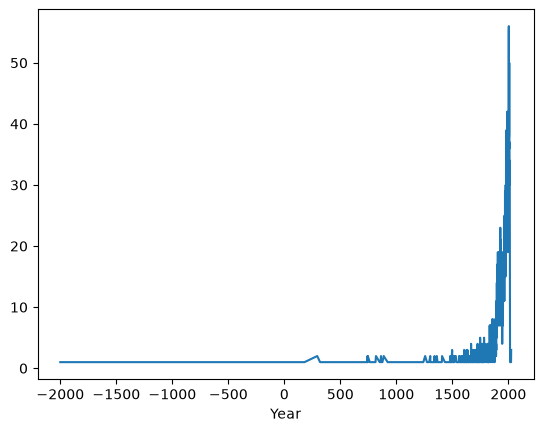

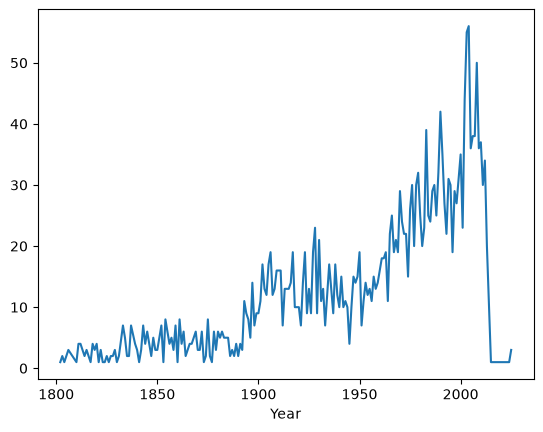

<Axes: xlabel='Year'>

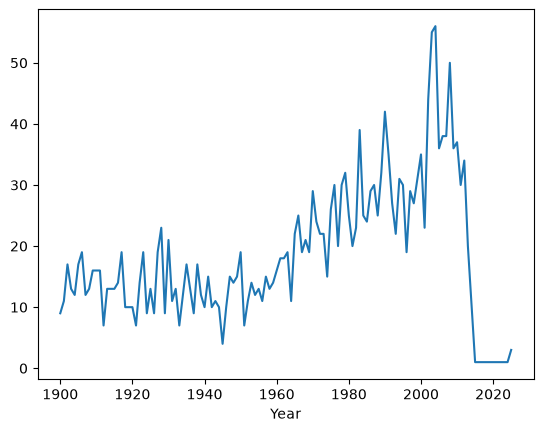

In [73]:
# 1.2
df12 = df1.loc[df1['Ms'] > 3.0].groupby('Year')['Ms'].count()
df12.plot()
plt.show()
df12[df12.index >= 1800].plot()
plt.show()
df12[df12.index >= 1900].plot()
# 地震次数的整体趋势是上升的，但是短时间尺度波动，上升的主要原因是观测能力的提升，波动是随机性和局部因素叠加的结果，地震分布近似泊松过程

In [76]:
# 1.3
def CountEq_LargestEq(country):
    n = df1.groupby('Country')['Id'].count()[country.upper()]
    df13 = df1.loc[df1['Country'] == country.upper()].sort_values('Ms', ascending = False).iloc[0]
    date = [df13['Year'], df13['Mo'], df13['Dy']]
    date = ['' if pd.isna(i) else int(i) for i in date]
    location = df13['Location Name']  
    return int(n), f'{date[0]}-{date[1]}-{date[2]}', location

result = [CountEq_LargestEq(c) for c in df1.groupby('Country').size().index]
result.sort(reverse = True)
for r in result:
    print(r)

(627, '1920-12-16', 'CHINA:  GANSU PROVINCE, SHANXI PROVINCE')
(429, '869-7-13', 'JAPAN:  SANRIKU')
(427, '2004-12-26', 'INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST')
(385, '856-12-22', 'IRAN:  DAMGHAN, QUMIS')
(359, '1999-8-17', 'TURKEY:  ISTANBUL, KOCAELI, SAKARYA')
(338, '1915-1-13', 'ITALY:  MARSICA, AVEZZANO, ABRUZZI')
(296, '365-7-21', 'GREECE:  CRETE:  KNOSSOS')
(283, '1957-3-9', 'ALASKA')
(233, '1897-9-21', 'PHILIPPINES:  MINDANAO, ZAMBOANGA, SULU, ISABELA')
(217, '1787-3-28', 'MEXICO:  SAN MARCOS, OAXACA')
(200, '1730-7-8', 'CHILE:  VALPARAISO')
(195, '1619-2-14', 'PERU:  TRUJILLO, PIURA, SANTA')
(159, '1952-11-4', 'RUSSIA:  KAMCHATKA PENINSULA')
(107, '2000-11-16', 'PAPUA NEW GUINEA:  NEW IRELAND, DUKE OF YORK')
(103, '1920-6-5', 'TAIWAN')
(102, '1897-6-12', 'INDIA:  ASSAM; BANGLADESH')
(83, '1904-1-20', 'PANAMA-COLOMBIA')
(72, '1909-7-7', 'AFGHANISTAN:  HINDU-KUSH')
(72, '1826--', 'NEW ZEALAND:  FJORDLAND')
(70, '1906-1-31', 'ECUADOR:  OFF COAST')
(65, '1913-10-14', 'VANUATU

C:\Users\lenovo\AppData\Local\Temp\ipykernel_17500\4025935444.py:2: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  df2 = pd.read_csv('Baoan_Weather_1998_2022.csv')


Text(0, 0.5, 'monthly mean air temperature')

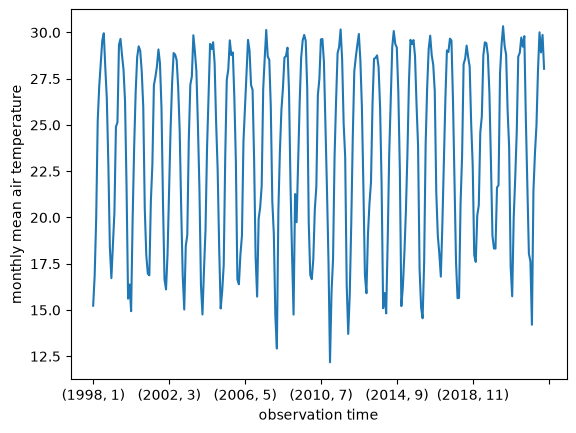

In [77]:
# 2
df2 = pd.read_csv('Baoan_Weather_1998_2022.csv')
vq = df2["TMP"].str.partition(",")
tmp_v = pd.to_numeric(vq[0])
tmp_v = tmp_v.where(tmp_v != 9999, np.nan)
df2['TMP_V'] = tmp_v / 10
df2["Y"] = pd.to_datetime(df2["DATE"]).dt.year
df2["M"] = pd.to_datetime(df2["DATE"]).dt.month
monthly = df2.groupby(["Y", "M"])["TMP_V"].mean()
monthly.plot()
plt.xlabel('observation time')
plt.ylabel('monthly mean air temperature')

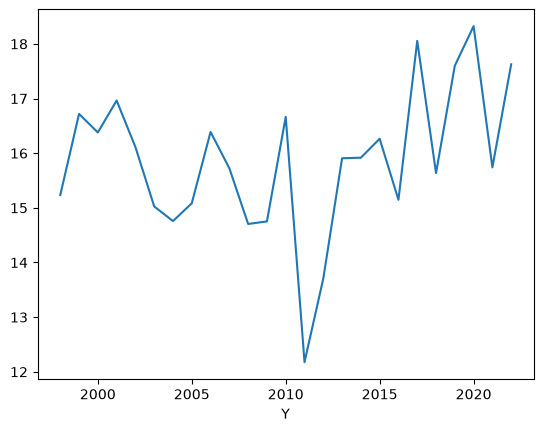

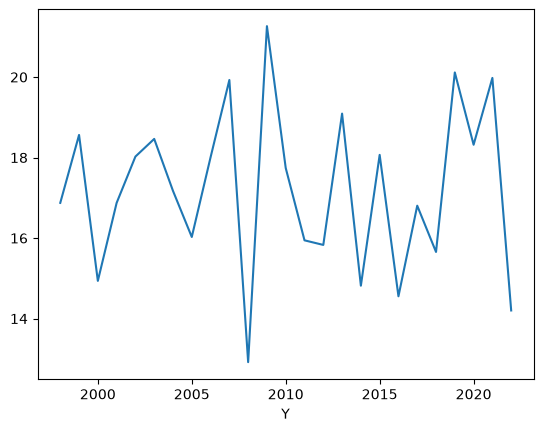

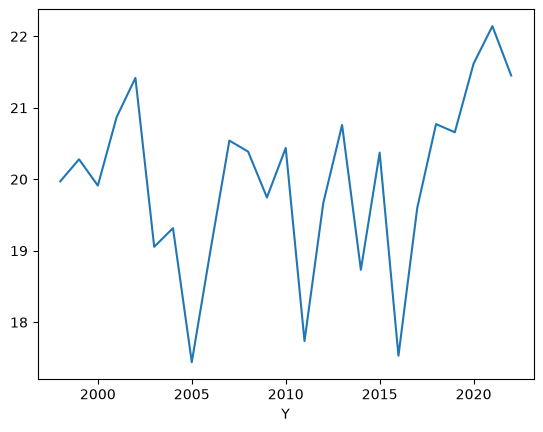

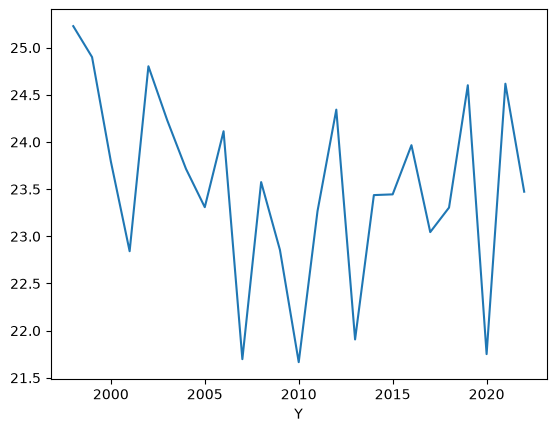

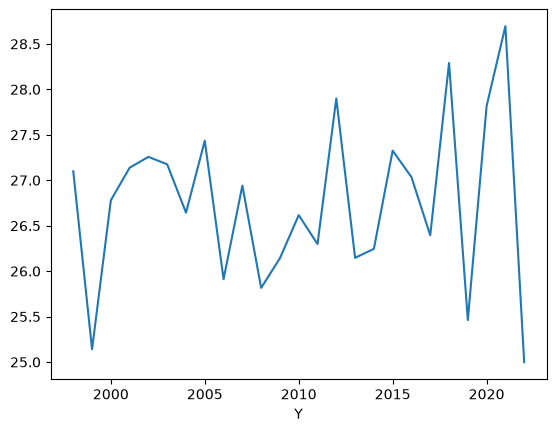

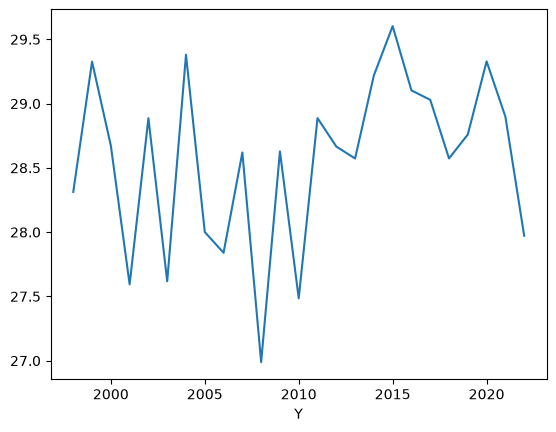

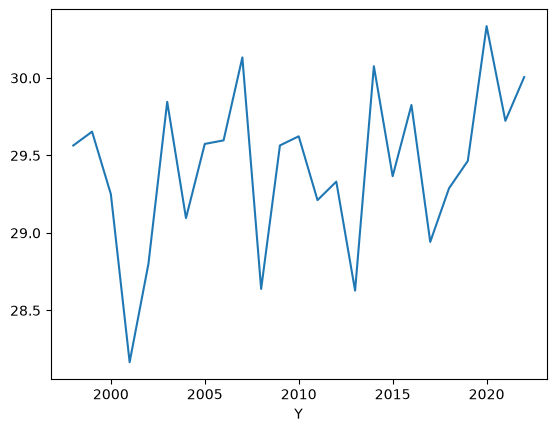

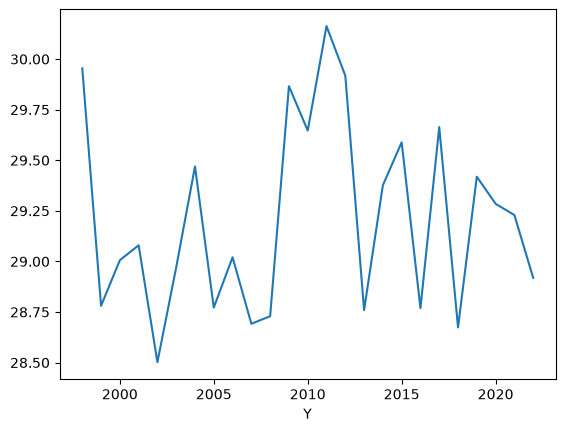

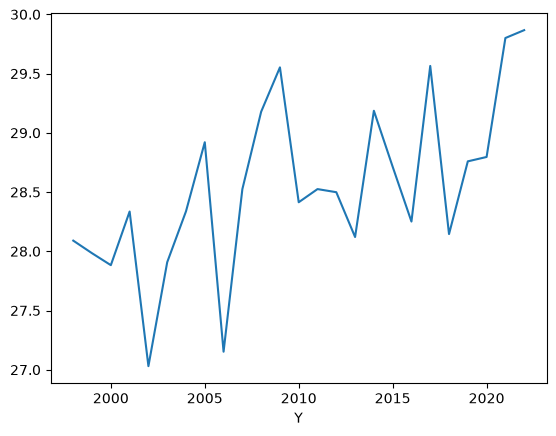

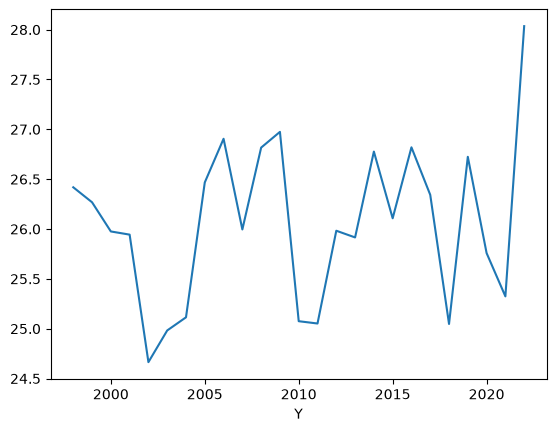

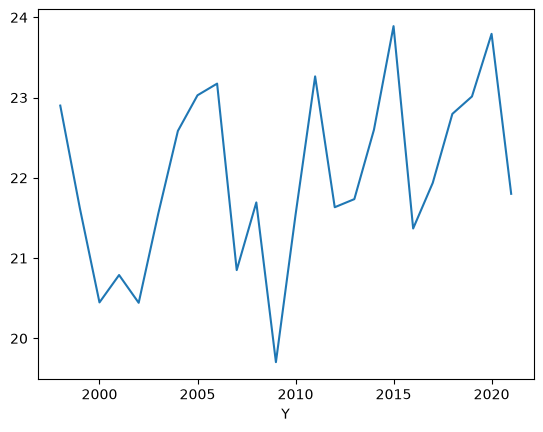

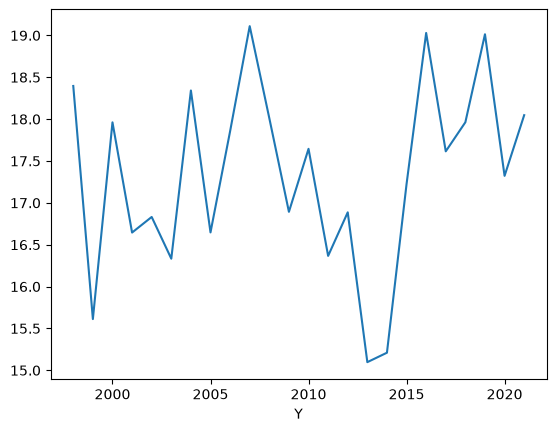

In [78]:
for i in range(12):
    df2.loc[df2['M']==i+1].groupby('Y')['TMP_V'].mean().plot()
    plt.show()

In [79]:
# 3
df3 = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),
                 skiprows=[1], 
                 parse_dates=['ISO_TIME'],
                 na_values=[' '],
                 dtype={'WMO_WIND':'float64'})

C:\Users\lenovo\AppData\Local\Temp\ipykernel_17500\4279954052.py:2: DtypeWarning: Columns (0: WMO_AGENCY) have mixed types. Specify dtype option on import or set low_memory=False.
  df3 = pd.read_csv('ibtracs.ALL.list.v04r00.csv',


In [81]:
# 3.1
df31 = df3.groupby('SID')['WMO_WIND'].max().sort_values(ascending=False)[0:10]
for sid in df31.index:
    print(df3.loc[df3['SID'] == sid]['NAME'].iloc[0])

PATRICIA
ALLEN
WILMA
LINDA
GILBERT
NOT_NAMED
DORIAN
RICK
MITCH
IRMA


In [82]:
# 3.2
df32 = df3.groupby('SID')['WMO_WIND'].max().sort_values(ascending=False)[0:20].values
for ww in df32:
    print(ww)

185.0
165.0
160.0
160.0
160.0
160.0
160.0
155.0
155.0
155.0
155.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0
150.0


In [83]:
# 3.3
df3.groupby('BASIN').count()['SID']

BASIN
EP     62412
NI     55402
SA       119
SI    160668
SP     67119
WP    236576
Name: SID, dtype: int64

Text(0, 0.5, 'latitude')

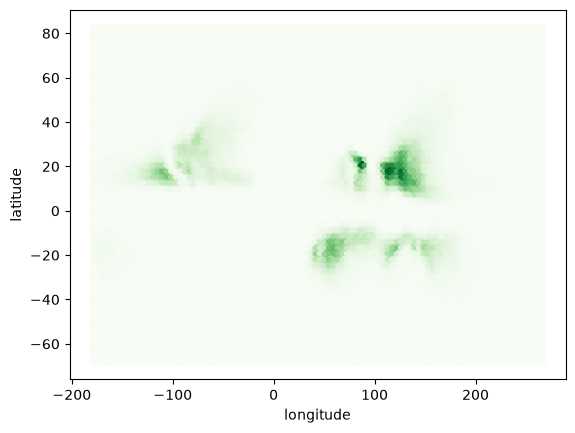

In [84]:
# 3.4
plt.hexbin(df3['LON'], df3['LAT'], gridsize = 100, cmap ='Greens')
plt.xlabel('longitude')
plt.ylabel('latitude')

Text(0, 0.5, 'latitude')

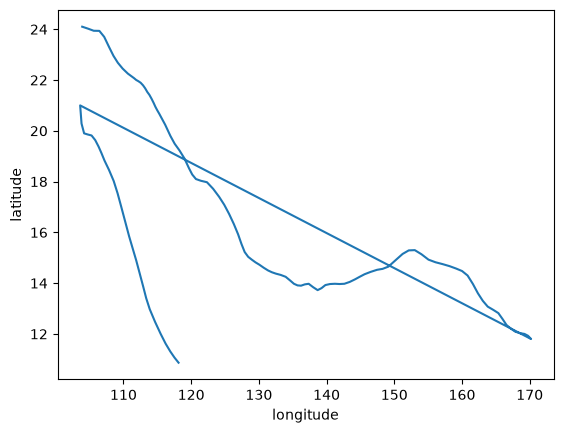

In [85]:
# 3.5
[lon, lat] = [df3.loc[df3['NAME'] == 'MANGKHUT']['LON'], df3.loc[df3['NAME'] == 'MANGKHUT']['LAT']]
plt.plot(lon, lat)
plt.xlabel('longitude')
plt.ylabel('latitude')

In [86]:
# 3.6
df3_new = df3.loc[(df3['SEASON'] >= 1970) & ((df3['BASIN'] == 'EP') | (df3['BASIN'] == 'WP'))]
df3_new

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
350394,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 00:00:00,TS,7.00000,151.400,NaN,1006.0,tokyo,main,1088,1088.0,_OO___________
350395,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 03:00:00,TS,7.24752,151.205,NaN,NaN,NaN,main,1109,1109.0,_PP___________
350396,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 06:00:00,TS,7.50000,151.000,NaN,1002.0,tokyo,main,1143,1143.0,_OO___________
350397,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 09:00:00,TS,7.75747,150.772,NaN,NaN,NaN,main,1171,1168.0,_PP___________
350398,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 12:00:00,TS,8.00000,150.500,NaN,998.0,tokyo,main,1182,1179.0,_OO___________
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
707085,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 15:00:00,TS,13.99570,-90.294,NaN,NaN,NaN,PROVISIONAL,0,0.0,P_____________
707086,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 18:00:00,NR,14.50000,-91.000,NaN,NaN,NaN,PROVISIONAL,0,NaN,O_____________
707174,2022286N15151,2022,80,WP,MM,NOT_NAMED,2022-10-12 12:00:00,NR,15.20000,151.300,NaN,NaN,NaN,PROVISIONAL,1985,1974.0,O_____________
707175,2022286N15151,2022,80,WP,MM,NOT_NAMED,2022-10-12 15:00:00,NR,15.05000,151.325,NaN,NaN,NaN,PROVISIONAL,1974,1952.0,P_____________


Text(0, 0.5, 'the number of datapoints')

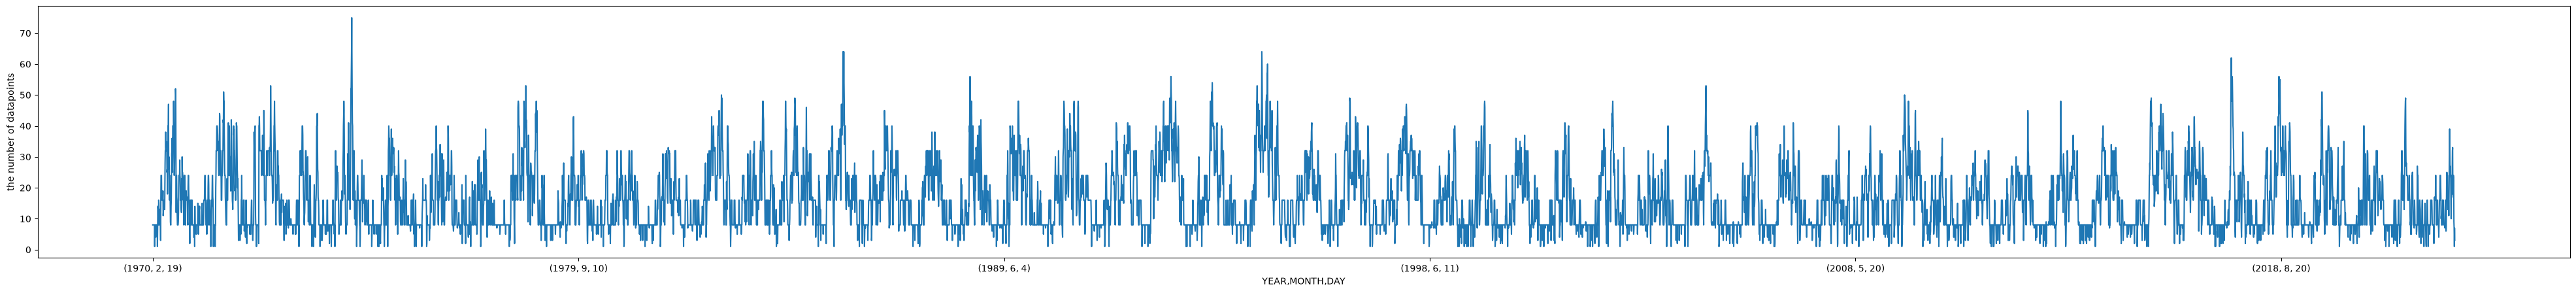

In [87]:
# 3.7
fig, ax = plt.subplots(figsize=(50, 5))
df3_new['YEAR'] = df3_new['ISO_TIME'].dt.year
df3_new['MONTH'] = df3_new['ISO_TIME'].dt.month
df3_new['DAY'] = df3_new['ISO_TIME'].dt.day
df3_new.groupby(['YEAR','MONTH','DAY']).size().plot()
plt.ylabel('the number of datapoints')

DOY
1      7.545455
2      8.000000
3      6.727273
4      7.750000
5      8.750000
         ...   
362    8.315789
363    6.947368
364    8.000000
365    8.454545
366    6.500000
Length: 366, dtype: float64


Text(0, 0.5, 'the climatology of datapoint counts')

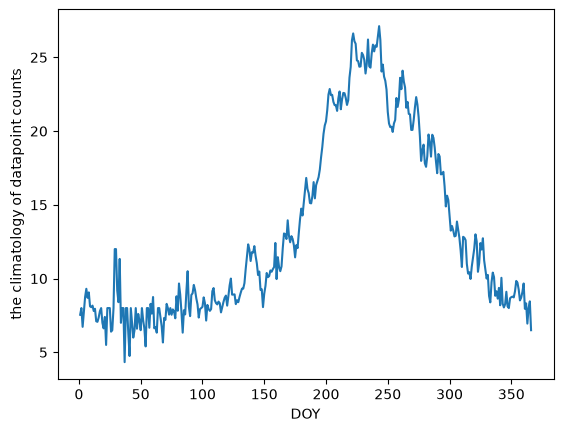

In [37]:
# 3.8
df3_new['DOY'] = df3_new['ISO_TIME'].dt.dayofyear
df38 = df3_new.groupby(['YEAR','DOY']).size().groupby('DOY').mean()
print(df38)
df38.plot()
plt.ylabel('the climatology of datapoint counts')

YEAR  DOY
1970  50      1.500000
      51      0.000000
      52      0.833333
      53      1.400000
      54      2.600000
               ...    
2022  277    -8.980769
      278   -11.693878
      282   -17.301887
      283   -12.769231
      285   -15.269231
Length: 10817, dtype: float64


Text(0, 0.5, 'the anomaly of daily counts from the climatology')

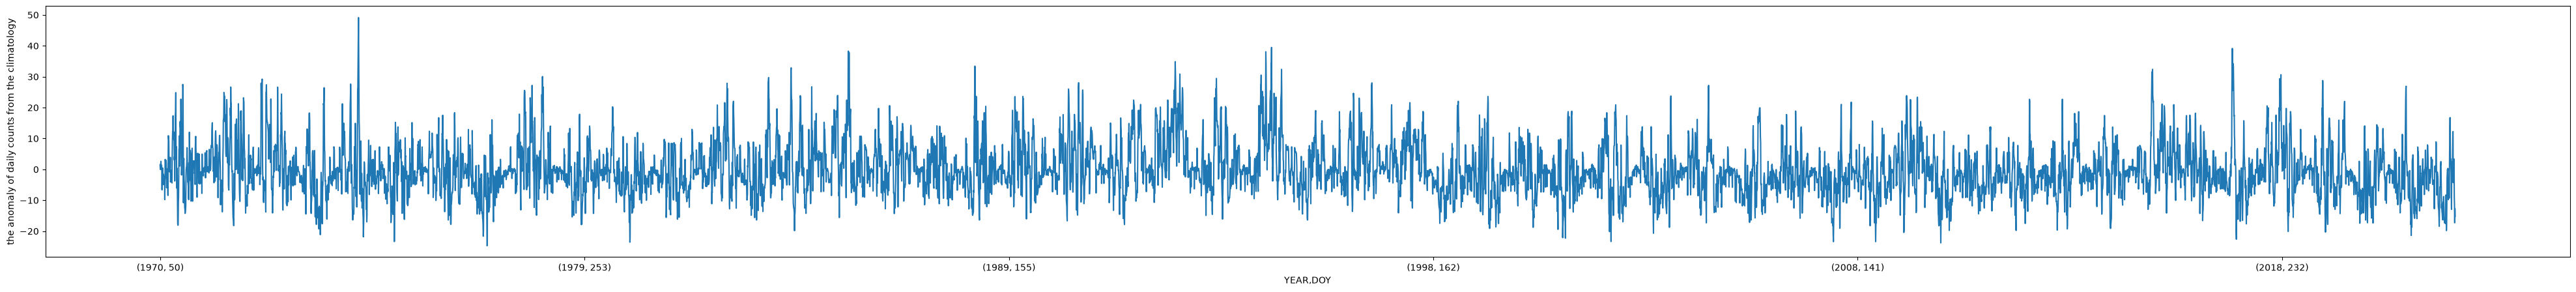

In [47]:
# 3.9
fig, ax = plt.subplots(figsize=(50, 5))
anom = df3_new.groupby(['YEAR','DOY']).size() - df38
print(anom)
anom.plot()
plt.ylabel('the anomaly of daily counts from the climatology')

In [50]:
# 3.10


In [55]:
# 4.1
df4 = pd.read_csv('US10adam004.csv',
                 parse_dates=['DATE'])
df4

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,DP01,DP01_ATTRIBUTES,DP10,DP10_ATTRIBUTES,...,EMSD,EMSD_ATTRIBUTES,EMSN,EMSN_ATTRIBUTES,EMXP,EMXP_ATTRIBUTES,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES
0,US10adam004,2005-04-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",9,",N",4,",N",...,0.0,",,N,30,+",0.0,",,N,30,+",13.5,",,N,11,",34.8,",,,N",0.0,",,,N"
1,US10adam004,2005-05-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",5,",N",2,",N",...,0.0,",,N,31,+",0.0,",,N,31,+",63.5,",,N,12,",68.6,",,,N",0.0,",,,N"
2,US10adam004,2005-06-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",12,",N",10,",N",...,0.0,",,N,30,+",0.0,",,N,30,+",49.5,",,N,10,",115.8,",,,N",0.0,",,,N"
3,US10adam004,2005-07-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",5,",N",3,",N",...,0.0,",,N,31,+",0.0,",,N,31,+",57.2,",,N,26,",81.5,",,,N",0.0,",,,N"
4,US10adam004,2005-08-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",9,",N",6,",N",...,0.0,",,N,31,+",0.0,",,N,31,+",67.3,",,N,18,",109.5,",,,N",0.0,",,,N"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193,US10adam004,2021-08-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",6,",N",3,",N",...,NaN,NaN,NaN,NaN,30.7,",,N,20,",49.4,",,,N",NaN,NaN
194,US10adam004,2021-09-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",6,",N",3,",N",...,NaN,NaN,NaN,NaN,21.1,",,N,03,",49.6,",,,N",NaN,NaN
195,US10adam004,2021-10-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",5,",N",4,",N",...,NaN,NaN,NaN,NaN,24.6,",,N,13,",59.7,",,,N",NaN,NaN
196,US10adam004,2021-11-01,40.4798,-98.4026,570.0,"AYR 3.5 NE, NE US",4,",N",2,",N",...,NaN,NaN,NaN,NaN,3.8,",,N,02,",8.1,",,,N",NaN,NaN


Text(0, 0.5, 'PRCP')

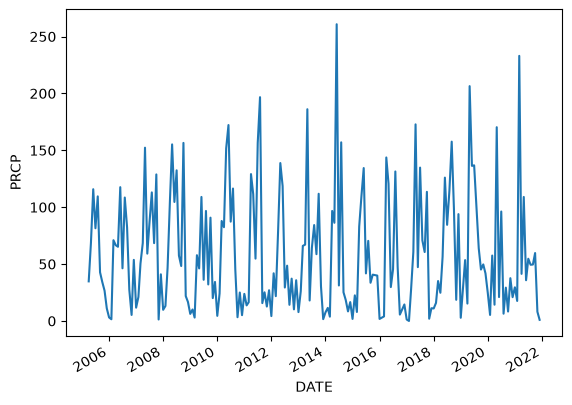

In [61]:
# 4.2
df4.set_index('DATE')['PRCP'].plot()
plt.ylabel('PRCP')

In [65]:
# 4.3
print(df4["PRCP"].min(), df4["PRCP"].max())
print(df4["PRCP"].mean())
print(df4["PRCP"].skew())
print(df4["PRCP"].kurt())

0.0 260.8
59.254545454545465
1.1299243502658727
0.9626071734117443
